# Hysteresis, closure and no-action bands

Family 32. The deadline belongs to the immutable state and is never rolled forward. Closed states are absorbing. Holding wins a tie after switching preferences; mandatory feasible actions override waiting.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Public workflow

The executable example uses only supplied or generated inputs.

In [2]:
"""Family 32: immutable fixed-deadline lifecycle and no-action bands."""
from convexity.math import policies

rule = policies.Hysteresis(entry=.9, exit=.6, convergence_gap=.01)
state = policies.PolicyState(deadline=20.)
for time, probability, gap in [(0., .95, .1), (5., .8, .06), (10., .82, .03), (15., .99, .009), (16., 1., .1)]:
    state = rule.update(state, probability, time, gap=gap)
    print(time, state.mode, state.reason)
print('Hold wins after switching cost:', policies.no_action([5., 5.5], switching=.5))
print('Mandatory override:', policies.no_action([5., 1.], mandatory=1))


0.0 active activation
5.0 active retained
10.0 active retained
15.0 closed convergence
16.0 closed convergence
Hold wins after switching cost: ActionDecision(action=0, value=5.0, holding_value=5.0, advantage=0.0, reason='hold')
Mandatory override: ActionDecision(action=1, value=1.0, holding_value=5.0, advantage=-4.0, reason='mandatory')


## A fixed lifecycle and a switching boundary

A probability dip inside the hysteresis band retains activation. Falling to the exit threshold closes the record even if confidence later recovers. This lifecycle is distinct from the choice to hold zero exposure.

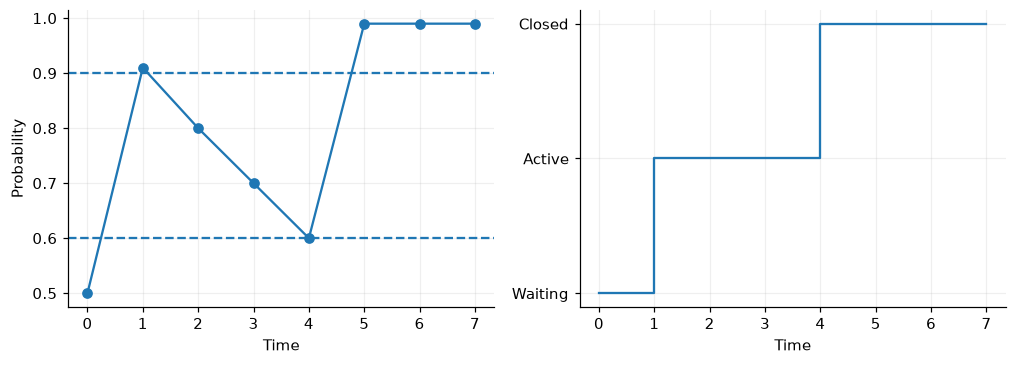

,Alternative advantage,Chosen action
0,0.0,0
1,0.1,0
2,0.2,0
3,0.3,0
4,0.4,0
5,0.5,0
6,0.6,1
7,0.7,1
8,0.8,1
9,0.9,1


In [3]:
times = np.arange(8.)
probabilities = [.5, .91, .8, .7, .6, .99, .99, .99]
s = policies.PolicyState(7.)
modes = []
for t, p in zip(times, probabilities):
    s = rule.update(s, p, t)
    modes.append({'waiting': 0, 'active': 1, 'closed': 2}[s.mode])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(times, probabilities, marker='o'); axes[0].axhline(.9, linestyle='--'); axes[0].axhline(.6, linestyle='--')
axes[0].set(xlabel='Time', ylabel='Probability')
axes[1].step(times, modes, where='post'); axes[1].set(yticks=[0, 1, 2], yticklabels=['Waiting', 'Active', 'Closed'], xlabel='Time')
plt.show()
gains = np.linspace(0, 1, 11)
display(pd.DataFrame({'Alternative advantage': gains,
    'Chosen action': [policies.no_action([5., 5.+g], switching=.5).action for g in gains]}))

## Scope of this evidence

These experiments illustrate the declared finite catalog, not live trading performance. See the [contracts and limitations](../docs/decision_mathematics.md) and `tests/math/decisions/` for mathematical acceptance checks.